<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Log%C3%ADstica_SLA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# bases

df_orders = pd.read_csv('/content/olist_orders_dataset.csv')

In [ ]:
# visualização

df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
df_leadtime = df_orders[[
    'order_id',
    'order_status',
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]].copy()

df_leadtime.head()

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02


In [ ]:
# transformando as datas

colunas_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

for coluna in colunas_data:
    df_leadtime[coluna] = pd.to_datetime(
        df_leadtime[coluna],
        errors='coerce'
    )

In [ ]:
# Tempo entre compra e aprovação
df_leadtime['tempo_aprovacao_horas'] = (
    df_leadtime['order_approved_at'] -
    df_leadtime['order_purchase_timestamp']
).dt.total_seconds() / 3600

# Tempo entre aprovação e postagem
df_leadtime['tempo_postagem_horas'] = (
    df_leadtime['order_delivered_carrier_date'] -
    df_leadtime['order_approved_at']
).dt.total_seconds() / 3600

# Tempo entre postagem e entrega
df_leadtime['tempo_entrega_horas'] = (
    df_leadtime['order_delivered_customer_date'] -
    df_leadtime['order_delivered_carrier_date']
).dt.total_seconds() / 3600

# Lead time total: compra até entrega
df_leadtime['lead_time_total_dias'] = (
    df_leadtime['order_delivered_customer_date'] -
    df_leadtime['order_purchase_timestamp']
).dt.total_seconds() / 86400

df_leadtime.head()

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,tempo_aprovacao_horas,tempo_postagem_horas,tempo_entrega_horas,lead_time_total_dias
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,0.178333,56.795833,145.503611,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,30.713889,11.109167,288.945833,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,0.276111,4.910278,220.274722,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,0.298056,89.900000,226.811944,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,1.030556,21.434722,46.507778,2.873877


In [ ]:
# tempo médio

indicadores = df_leadtime[
    df_leadtime['order_status'] == 'delivered'
][[
    'tempo_aprovacao_horas',
    'tempo_postagem_horas',
    'tempo_entrega_horas',
    'lead_time_total_dias'
]]

indicadores.mean().round(2)

,0
tempo_aprovacao_horas,10.28
tempo_postagem_horas,67.18
tempo_entrega_horas,223.93
lead_time_total_dias,12.56


In [ ]:
resumo_leadtime = pd.DataFrame({
    'Etapa': [
        'Compra até aprovação',
        'Aprovação até postagem',
        'Postagem até entrega',
        'Lead time total'
    ],
    'Tempo médio': [
        indicadores['tempo_aprovacao_horas'].mean(),
        indicadores['tempo_postagem_horas'].mean(),
        indicadores['tempo_entrega_horas'].mean(),
        indicadores['lead_time_total_dias'].mean()
    ],
    'Unidade': ['Horas', 'Horas', 'Horas', 'Dias']
})

resumo_leadtime

,Etapa,Tempo médio,Unidade
0,Compra até aprovação,10.276767,Horas
1,Aprovação até postagem,67.177826,Horas
2,Postagem até entrega,223.927129,Horas
3,Lead time total,12.558217,Dias


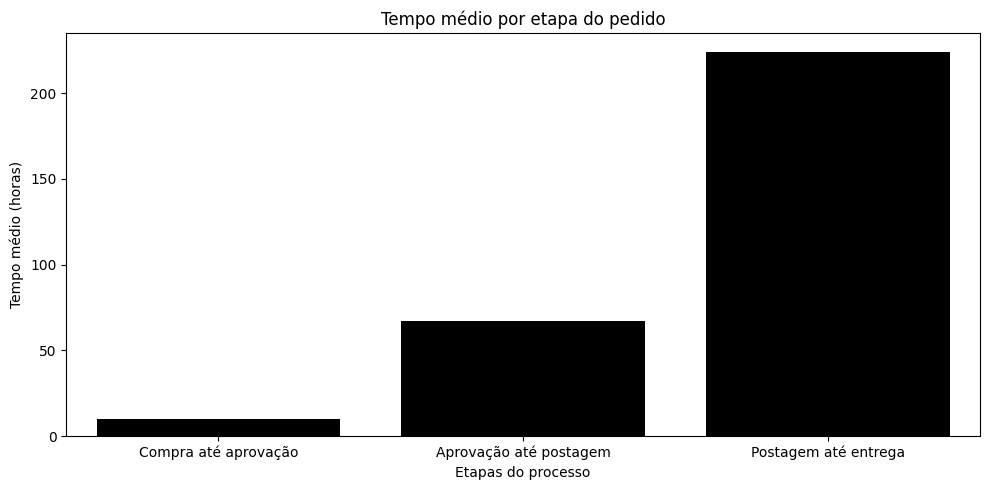

In [ ]:
# Visualização gráfico

etapas = resumo_leadtime.iloc[:3]

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=etapas,
    x='Etapa',
    y='Tempo médio',
    color='black',
    ax=ax
)

plt.title('Tempo médio por etapa do pedido')
plt.xlabel('Etapas do processo')
plt.ylabel('Tempo médio (horas)')
plt.xticks(rotation=0)

# Fundo transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()

# Salvar imagem com fundo transparente
plt.savefig(
    'tempo_medio_etapas.png',
    transparent=True,
    dpi=300,
    bbox_inches='tight'
)

plt.show()


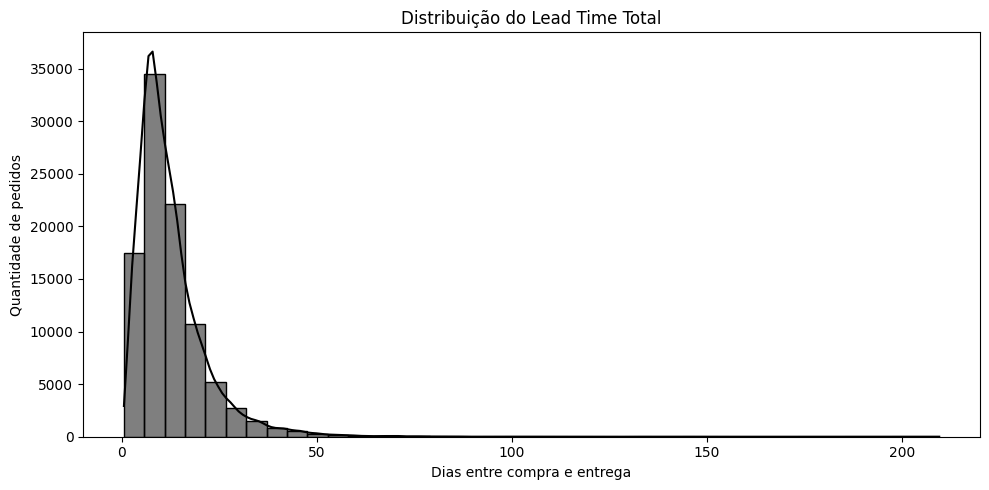

In [ ]:
# distribuição


fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df_leadtime[
        df_leadtime['order_status'] == 'delivered'
    ],
    x='lead_time_total_dias',
    bins=40,
    kde=True,
    color='black',
    ax=ax
)

plt.title('Distribuição do Lead Time Total')
plt.xlabel('Dias entre compra e entrega')
plt.ylabel('Quantidade de pedidos')

# Fundo totalmente transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

# Remover linhas de grade
ax.grid(False)

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    'grafico_leadtime.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)

plt.show()


In [ ]:
# mediana e %

df_leadtime[
    df_leadtime['order_status'] == 'delivered'
]['lead_time_total_dias'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).round(2)

,lead_time_total_dias
count,96470.00
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
90%,23.10
95%,29.27
max,209.63


In [ ]:
# correlação entre atrasos e review_score

df_reviews = pd.read_csv('/content/olist_order_reviews_dataset.csv')

In [ ]:
# Selecionar as colunas necessárias
df_orders_atraso = df_orders[[
    'order_id',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]].copy()

df_reviews2 = df_reviews[[
    'order_id',
    'review_score'
]].copy()

# Converter datas
colunas_data = [
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_data:
    df_orders_atraso[coluna] = pd.to_datetime(
        df_orders_atraso[coluna],
        errors='coerce'
    )

# Integrar as bases
df_atraso_reviews = df_orders_atraso.merge(
    df_reviews,
    on='order_id',
    how='inner'
)

df_atraso_reviews.head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,a54f0611adc9ed256b57ede6b6eb5114,4,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,8d5266042046a06655c8db133d120ba5,4,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,359d03e676b3c069f62cadba8dd3f6e8,5,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,e50934924e227544ba8246aeb3770dd4,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51


In [ ]:
# dias de atraso

df_atraso_reviews['dias_atraso'] = (
    df_atraso_reviews['order_delivered_customer_date'] -
    df_atraso_reviews['order_estimated_delivery_date']
).dt.total_seconds() / 86400

In [ ]:
df_atraso_reviews['situacao_entrega'] = (
    df_atraso_reviews['dias_atraso']
    .apply(lambda x: 'Atrasado' if x > 0 else 'No prazo')
)

In [ ]:
avaliacao_atraso = df_atraso_reviews.groupby(
    'situacao_entrega'
)['review_score'].mean()

print(avaliacao_atraso)

situacao_entrega
Atrasado    2.566550
No prazo    4.214307
Name: review_score, dtype: float64


In [ ]:
correlacao = df_atraso_reviews[
    ['dias_atraso', 'review_score']
].corr(method='spearman')

print(correlacao)

              dias_atraso  review_score
dias_atraso      1.000000     -0.175612
review_score    -0.175612      1.000000


In [ ]:
correlacao_valor = correlacao.loc[
    'dias_atraso',
    'review_score'
]

print('Correlação:', round(correlacao_valor, 3))

Correlação: -0.176


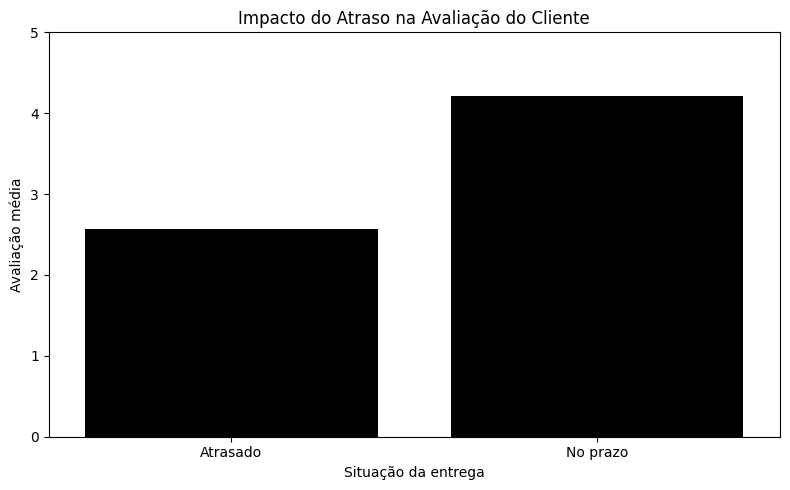

In [ ]:
# visualização gráfico

# Média das avaliações por situação da entrega
avaliacao_atraso = (
    df_atraso_reviews
    .groupby('situacao_entrega')['review_score']
    .mean()
    .reset_index()
)

# Criar gráfico
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=avaliacao_atraso,
    x='situacao_entrega',
    y='review_score',
    color='black',
    ax=ax
)

plt.title('Impacto do Atraso na Avaliação do Cliente')
plt.xlabel('Situação da entrega')
plt.ylabel('Avaliação média')
plt.ylim(0, 5)

# Deixar fundo totalmente transparente
fig.patch.set_facecolor('none')
ax.set_facecolor('none')
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

# Remover linhas de grade
ax.grid(False)

plt.tight_layout()

# Salvar PNG com fundo transparente
plt.savefig(
    'avaliacao_atraso.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)

plt.show()


In [ ]:
# adicionando base de customers

df_customers = pd.read_csv('/content/olist_customers_dataset.csv')

In [ ]:
# Selecionar colunas necessárias
df_regiao = df_orders[[
    'order_id',
    'customer_id',
    'order_status',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]].copy()

df_clientes = df_customers[[
    'customer_id',
    'customer_state'
]].copy()

df_order_reviews = df_reviews[[
    'order_id',
    'review_score'
]].copy()

# Converter datas
colunas_data = [
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_data:
    df_regiao[coluna] = pd.to_datetime(
        df_regiao[coluna],
        errors='coerce'
    )

# Integrar as bases
df_regiao = df_regiao.merge(
    df_clientes,
    on='customer_id',
    how='left'
)

# Calcular uma nota média por pedido
df_reviews = df_reviews.groupby(
    'order_id',
    as_index=False
)['review_score'].mean()

df_regiao = df_regiao.merge(
    df_reviews,
    on='order_id',
    how='left'
)

df_regiao.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,SP,5.0


In [ ]:
colunas_data = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_data:
    df_regiao[coluna] = pd.to_datetime(
        df_regiao[coluna],
        errors='coerce'
    )

In [ ]:
# Calcular dias de entrega
df_regiao['dias_entrega'] = (
    df_regiao['order_delivered_customer_date'] -
    df_regiao['order_purchase_timestamp']
).dt.total_seconds() / 86400

In [ ]:
df_regiao['dias_atraso'] = (
    df_regiao['order_delivered_customer_date'] -
    df_regiao['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Classificar entregas
df_regiao['entrega_no_prazo'] = (
    df_regiao['dias_atraso'] <= 0
)

In [ ]:
# Considerar somente pedidos entregues
df_entregues = df_regiao[
    df_regiao['order_status'] == 'delivered'
].copy()

# Agrupar por estado
desempenho_regional = df_entregues.groupby(
    'customer_state'
).agg(
    nota_media=('review_score', 'mean'),
    tempo_medio_entrega=('dias_entrega', 'mean'),
    percentual_no_prazo=('entrega_no_prazo', 'mean'),
    total_pedidos=('order_id', 'nunique')
).reset_index()

# Converter percentual para %
desempenho_regional['percentual_no_prazo'] *= 100

desempenho_regional = desempenho_regional.round(2)

desempenho_regional.sort_values(
    'nota_media',
    ascending=False
)

,customer_state,nota_media,tempo_medio_entrega,percentual_no_prazo,total_pedidos
25,SP,4.25,8.76,94.09,40501
3,AP,4.24,27.19,95.52,67
2,AM,4.24,26.43,95.86,145
17,PR,4.24,11.99,95.00,4923
22,RS,4.19,15.30,92.83,5345
10,MG,4.19,12.01,94.39,11354
20,RO,4.17,19.37,97.12,243
11,MS,4.16,15.62,88.45,701
26,TO,4.15,17.66,87.23,274
19,RN,4.15,19.28,89.24,474


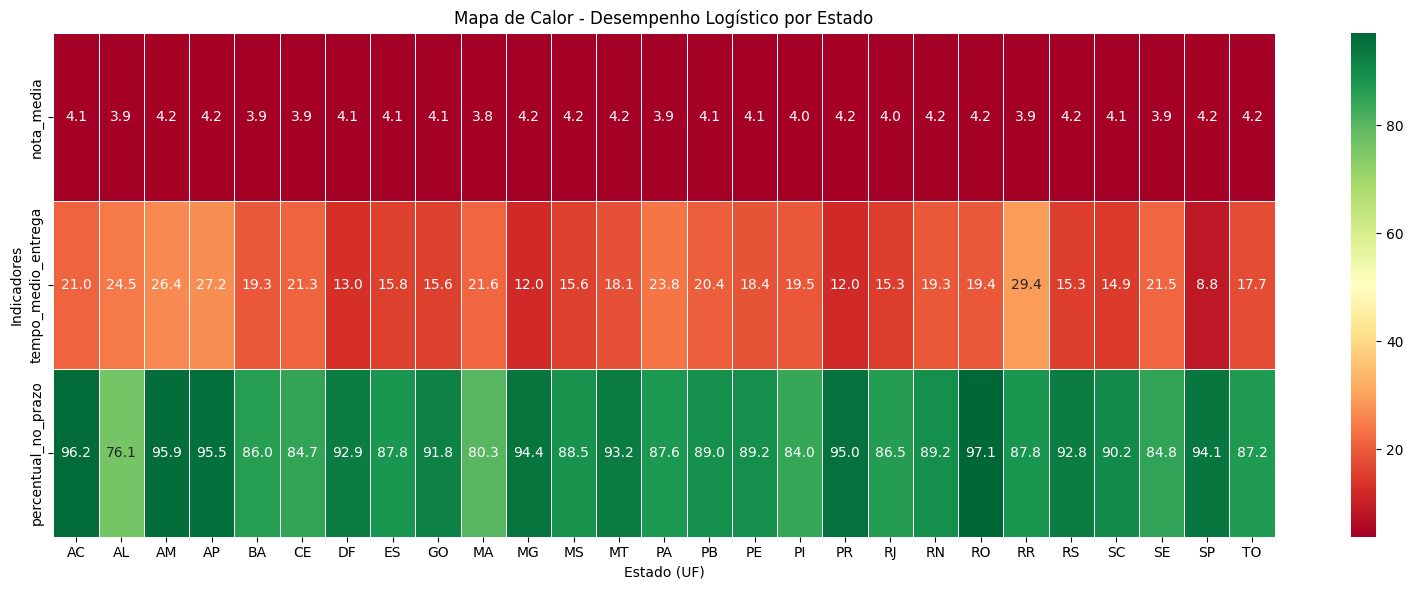

In [ ]:
fig, ax = plt.subplots(figsize=(16, 6))

heatmap_data = desempenho_regional.set_index(
    'customer_state'
)[[
    'nota_media',
    'tempo_medio_entrega',
    'percentual_no_prazo'
]].T

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax
)

plt.title('Mapa de Calor - Desempenho Logístico por Estado')
plt.xlabel('Estado (UF)')
plt.ylabel('Indicadores')

# Fundo transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)
fig.patch.set_facecolor('none')
ax.set_facecolor('none')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    'mapa_calor_desempenho_regional.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)

plt.show()

In [ ]:
# Filtrar pedidos entregues com datas válidas
df_ranking = df_regiao[
    (df_regiao['order_status'] == 'delivered') &
    (df_regiao['order_delivered_customer_date'].notna()) &
    (df_regiao['order_estimated_delivery_date'].notna()) &
    (df_regiao['customer_state'].notna())
].copy()

In [ ]:
# Classificar entregas
df_ranking['entrega_no_prazo'] = (
    df_ranking['dias_atraso'] <= 0
)

# Agrupar por estado
ranking_estados = df_ranking.groupby('customer_state').agg(
    total_pedidos=('order_id', 'nunique'),
    entregas_no_prazo=('entrega_no_prazo', 'sum'),
    percentual_no_prazo=('entrega_no_prazo', 'mean')
).reset_index()

# Converter para percentual
ranking_estados['percentual_no_prazo'] *= 100

In [ ]:
top_5 = ranking_estados.sort_values(
    by='percentual_no_prazo',
    ascending=False
).head(5).copy()

top_5.insert(0, 'Ranking', range(1, 6))

top_5.round(2)

,Ranking,customer_state,total_pedidos,entregas_no_prazo,percentual_no_prazo
20,1,RO,243,236,97.12
0,2,AC,80,77,96.25
2,3,AM,145,139,95.86
3,4,AP,67,64,95.52
17,5,PR,4923,4677,95.00


In [ ]:
bottom_5 = ranking_estados.sort_values(
    by='percentual_no_prazo',
    ascending=True
).head(5).copy()

bottom_5.insert(0, 'Ranking', range(1, 6))

bottom_5.round(2)

,Ranking,customer_state,total_pedidos,entregas_no_prazo,percentual_no_prazo
1,1,AL,397,302,76.07
9,2,MA,717,576,80.33
16,3,PI,476,400,84.03
5,4,CE,1279,1083,84.68
24,5,SE,335,284,84.78


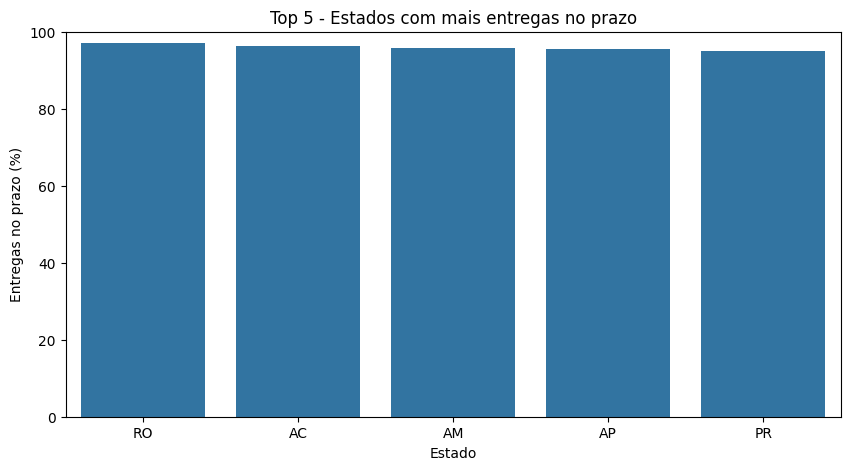

In [ ]:
#visualização gráfico

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_5,
    x='customer_state',
    y='percentual_no_prazo'
)

plt.title('Top 5 - Estados com mais entregas no prazo')
plt.xlabel('Estado')
plt.ylabel('Entregas no prazo (%)')
plt.ylim(0, 100)

plt.show()

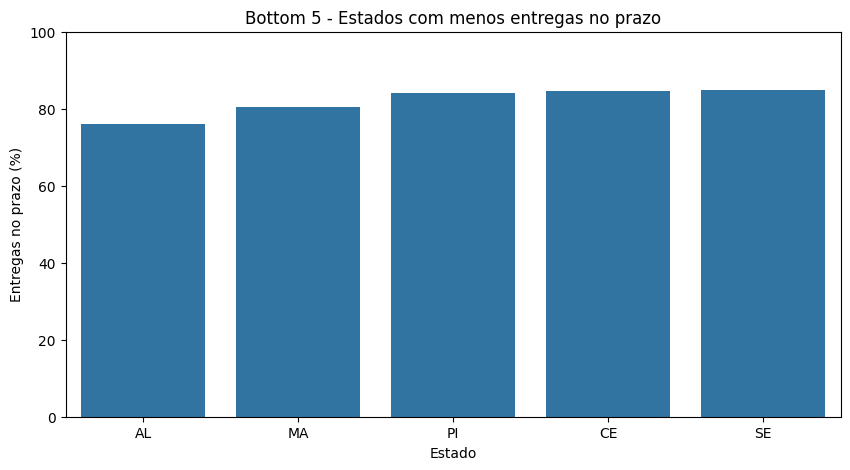

In [ ]:
#visualização gráfico

plt.figure(figsize=(10, 5))

sns.barplot(
    data=bottom_5,
    x='customer_state',
    y='percentual_no_prazo'
)

plt.title('Bottom 5 - Estados com menos entregas no prazo')
plt.xlabel('Estado')
plt.ylabel('Entregas no prazo (%)')
plt.ylim(0, 100)

plt.show()

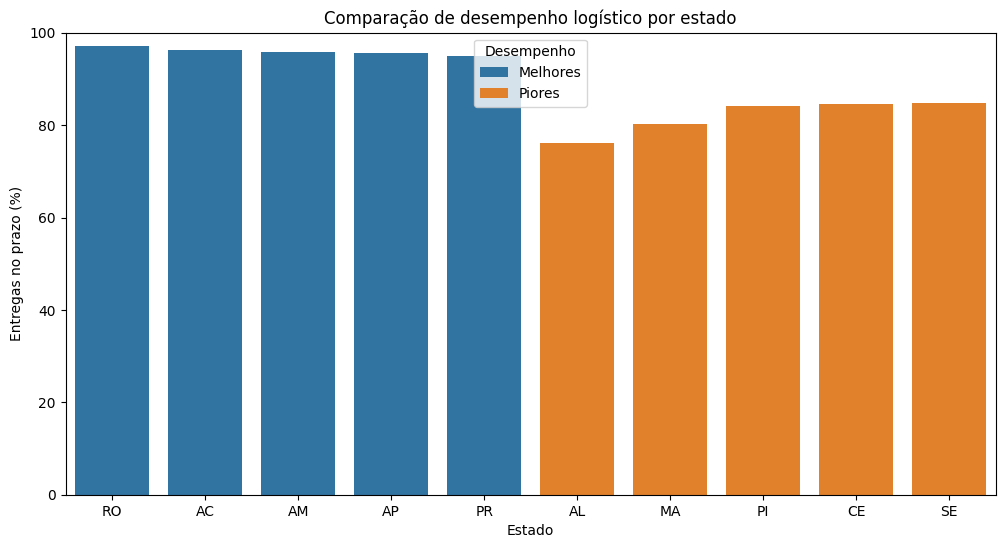

In [ ]:
# visualização gráfico comparativo

comparativo = pd.concat([
    top_5.assign(grupo='Melhores'),
    bottom_5.assign(grupo='Piores')
])

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparativo,
    x='customer_state',
    y='percentual_no_prazo',
    hue='grupo'
)

plt.title('Comparação de desempenho logístico por estado')
plt.xlabel('Estado')
plt.ylabel('Entregas no prazo (%)')
plt.ylim(0, 100)

plt.legend(title='Desempenho')
plt.show()

In [ ]:
# visão geral

media_geral = (
    df_ranking['entrega_no_prazo'].mean() * 100
)

print(f'Média geral de entregas no prazo: {media_geral:.2f}%')

print('\nEstados acima da média:')
print(
    ranking_estados[
        ranking_estados['percentual_no_prazo'] > media_geral
    ][['customer_state', 'percentual_no_prazo']]
    .sort_values('percentual_no_prazo', ascending=False)
)

Média geral de entregas no prazo: 91.89%

Estados acima da média:
   customer_state  percentual_no_prazo
20             RO            97.119342
0              AC            96.250000
2              AM            95.862069
3              AP            95.522388
17             PR            95.003047
10             MG            94.389642
25             SP            94.105300
12             MT            93.227991
6              DF            92.932692
22             RS            92.851796
